<a href="https://colab.research.google.com/github/Karolina-Dem/useful_programs/blob/main/colab_intro.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Colab Intro



In [55]:
# Obliczenie 2+2
wynik_dodawania = 2 + 2
print("Wynik działania 2 + 2 =", wynik_dodawania)

Wynik działania 2 + 2 = 4


In [56]:
import math
# Obliczenie pi^pi
wynik_potegowania = math.pi ** math.pi
print("Wynik działania pi^pi =", wynik_potegowania)

Wynik działania pi^pi = 36.4621596072079


## Obliczenia matematyczne: Ciąg geometryczny

Suma pierwszych $n$ wyrazów ciągu geometrycznego, gdzie $a_1$ to pierwszy wyraz, a $q$ to iloraz ciągu ($q \neq 1$), wyraża się wzorem:

$$S_n = a_1 \frac{1-q^n}{1-q}$$

Jeżeli $|q| < 1$, to przy $n \to \infty$ suma ta dąży do granicy (sumy szeregu geometrycznego):

$$S = \frac{a_1}{1-q}$$

In [57]:
# Komórka kodu licząca sumę kwadratów liczb od 1 do 100
suma_kwadratow_wyliczona = sum(i**2 for i in range(1, 101))
print(f"Suma kwadratów liczb od 1 do 100 wynosi: {suma_kwadratow_wyliczona}")

Suma kwadratów liczb od 1 do 100 wynosi: 338350


In [58]:
import os
# Komórka kodu zapisująca wynik sumy kwadratów do pliku colab_wynik.txt
with open("colab_wynik.txt", "w") as f:
    f.write(str(suma_kwadratow_wyliczona))

print(f"Wynik został pomyślnie zapisany w pliku: {os.path.abspath('colab_wynik.txt')}")

Wynik został pomyślnie zapisany w pliku: /content/colab_wynik.txt


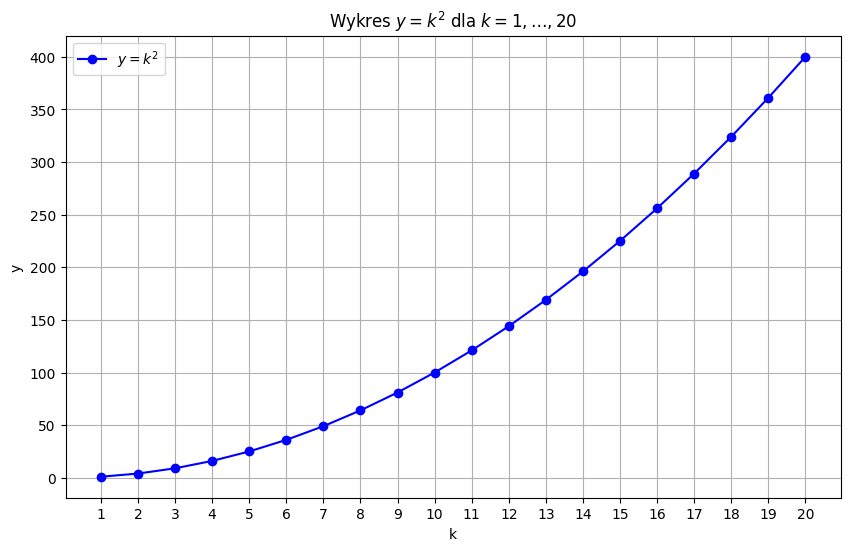

Zapisano wykres pod ścieżką: /content/wykres.png


In [59]:
import numpy as np
import matplotlib.pyplot as plt
import os

# Tworzenie wykresu y = k^2 dla k = 1, ..., 20
k = np.arange(1, 21)
y = k**2

plt.figure(figsize=(10, 6))
plt.plot(k, y, marker='o', linestyle='-', color='b', label=r'$y = k^2$')
plt.title(r'Wykres $y = k^2$ dla $k = 1, …, 20$')
plt.xlabel('k')
plt.ylabel('y')
plt.xticks(k)
plt.grid(True)
plt.legend()

# Zapis wykresu do pliku wykres.png
out_path = "wykres.png"
plt.savefig(out_path, dpi=150, bbox_inches="tight")
plt.show()

print("Zapisano wykres pod ścieżką:", os.path.abspath(out_path))

In [60]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import Video, display
import os

# 1. Upewnienie się, że ffmpeg jest zainstalowany w środowisku
print("Weryfikacja pakietu ffmpeg...")
!apt-get update -qq && apt-get install -y ffmpeg > /dev/null 2>&1

# 2. Parametry fizyczne wahadła
L = 1.0       # Długość ramienia (m)
g = 9.81      # Przyspieszenie ziemskie (m/s^2)
dt = 0.04     # Krok czasowy
t_max = 8.0   # Czas trwania
t = np.arange(0, t_max, dt)

theta0 = np.pi / 3  # Kąt początkowy
omega = np.sqrt(g / L)
theta = theta0 * np.cos(omega * t)

# Współrzędne x, y
x = L * np.sin(theta)
y = -L * np.cos(theta)

# 3. Przygotowanie wykresu
fig, ax = plt.subplots(figsize=(6, 6), facecolor='white')
ax.set_xlim(-1.2, 1.2)
ax.set_ylim(-1.2, 0.2)
ax.set_aspect('equal')
ax.axis('off')

line_rod, = ax.plot([], [], 'o-', lw=3, color='#1e3d59', markersize=4, zorder=2)
bob = ax.scatter([], [], s=200, color='#ff6e40', edgecolor='#1e3d59', linewidth=2, zorder=3)
trail, = ax.plot([], [], '-', lw=1.5, color='#ff6e40', alpha=0.3, zorder=1)
time_text = ax.text(0.05, 0.9, '', transform=ax.transAxes, fontsize=12, fontweight='bold', color='#17b978')

ax.plot(0, 0, 'k+', markersize=10, zorder=4)

def init():
    line_rod.set_data([], [])
    bob.set_offsets(np.empty((0, 2)))
    trail.set_data([], [])
    time_text.set_text('')
    return line_rod, bob, trail, time_text

def update(frame):
    line_rod.set_data([0, x[frame]], [0, y[frame]])
    bob.set_offsets([[x[frame], y[frame]]])
    trail_start = max(0, frame - 15)
    trail.set_data(x[trail_start:frame+1], y[trail_start:frame+1])
    time_text.set_text(f'Czas: {t[frame]:.2f} s')
    return line_rod, bob, trail, time_text

# 4. Generowanie animacji
ani = FuncAnimation(fig, update, frames=len(t), init_func=init, blit=True, interval=40)

# 5. Zapis do pliku video.mp4
video_path = "video.mp4"
print("Trwa generowanie i zapisywanie pliku MP4...")
ani.save(video_path, writer='ffmpeg', fps=25, dpi=100)
plt.close(fig)

print(f"Animacja zapisana pomyślnie pod ścieżką: {os.path.abspath(video_path)}")

# 6. Wyświetlenie wideo w notebooku za pomocą natywnego odtwarzacza Colab
display(Video(video_path, embed=True, width=400, height=400))

Weryfikacja pakietu ffmpeg...
W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Trwa generowanie i zapisywanie pliku MP4...
Animacja zapisana pomyślnie pod ścieżką: /content/video.mp4


### Konwersja animacji z MP4 do formatu GIF
Poniższa komórka wczytuje wygenerowany wcześniej plik `video.mp4` i konwertuje go na animowany plik `video.gif` przy użyciu biblioteki `moviepy`.

In [61]:
from moviepy.editor import VideoFileClip
import os

video_path = "video.mp4"
gif_path = "video.gif"

# Upewniamy się, czy plik MP4 na pewno istnieje przed konwersją
if os.path.exists(video_path):
    clip = VideoFileClip(video_path)
    clip.write_gif(gif_path, fps=15, program='ffmpeg')
    clip.close()
    print("Zapisano animowany GIF pod ścieżką:", os.path.abspath(gif_path))
else:
    print(f"Błąd: Plik {video_path} nie istnieje! Uruchom najpierw komórkę generującą animację wahadła (cell -QCZwp1jODV2).")

MoviePy - Building file  video.gif
MoviePy - - Generating GIF frames.


MoviePy - - File ready: video.gif.
Zapisano animowany GIF pod ścieżką: /content/video.gif


### Podgląd animacji (GIF) dla serwisu GitHub

Poniższy znacznik Markdown wczytuje wygenerowany plik `video.gif`. Dzięki temu animacja będzie automatycznie odtwarzana bezpośrednio podczas przeglądania tego notatnika na GitHubie (pamiętaj, aby przesłać plik `video.gif` do tego samego katalogu w repozytorium co ten notatnik):

![Animacja Wahadła](https://github.com/Karolina-Dem/useful_programs/blob/main/video.gif?raw=1)

### Generowanie i zapisywanie własnej krzywej parametrycznej
Poniższy kod generuje klasyczną krzywą parametryczną (np. spiralę Fermata lub trójlistnik/rozetę). Wynik zostaje wyświetlony na wykresie oraz zapisany jako plik graficzny `parametric_curve.png`.

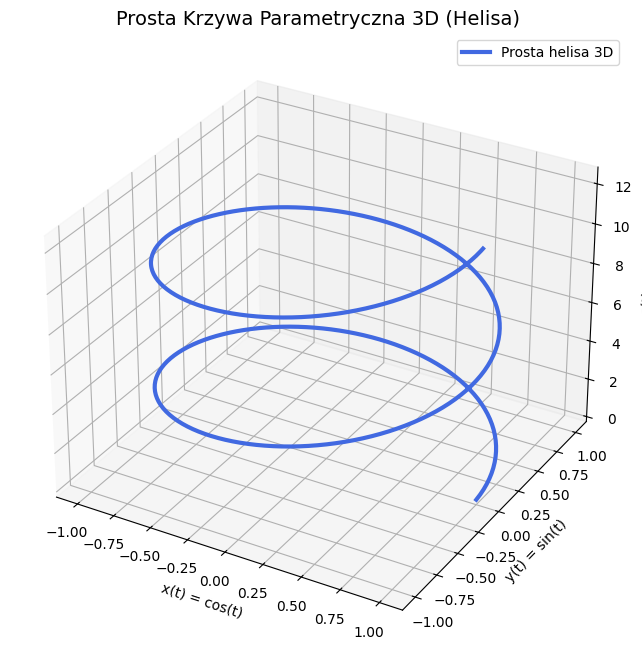

Zapisano prostą trójwymiarową krzywą parametryczną jako: /content/parametric_curve.png


In [62]:
# Correcting the label for rendering issue in matplotlib mathtext
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import os

# Parametric equations - prosta trójwymiarowa helisa (spirala)
t = np.linspace(0, 4 * np.pi, 500)
x = np.cos(t)
y = np.sin(t)
z = t

# 3D Plot
fig = plt.figure(figsize=(8, 8))
ax = fig.add_subplot(111, projection='3d')
ax.plot(x, y, z, label="Prosta helisa 3D", color="royalblue", linewidth=3)
ax.set_title("Prosta Krzywa Parametryczna 3D (Helisa)", fontsize=14)
ax.set_xlabel("x(t) = cos(t)")
ax.set_ylabel("y(t) = sin(t)")
ax.set_zlabel("z(t) = t")
ax.legend()

# Zapis do pliku
out_curve_path = "parametric_curve.png"
plt.savefig(out_curve_path, dpi=150, bbox_inches='tight')
plt.show()

print("Zapisano prostą trójwymiarową krzywą parametryczną jako:", os.path.abspath(out_curve_path))